In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

np.random.seed(42)
date_range = pd.date_range(start='1981-01-01', end='2023-12-31', freq='B')
n = len(date_range)
close_prices = 10 + np.cumsum(np.random.normal(0.05, 1.5, n))
close_prices = np.maximum(close_prices, 0.5)
open_prices = close_prices + np.random.normal(0, 0.5, n)
high_prices = np.maximum(open_prices, close_prices) + np.abs(np.random.normal(0, 0.8, n))
low_prices = np.minimum(open_prices, close_prices) - np.abs(np.random.normal(0, 0.8, n))
volume = np.random.randint(1000000, 50000000, n)

df = pd.DataFrame({
    'Date': date_range, 'Open': open_prices, 'High': high_prices,
    'Low': low_prices, 'Close': close_prices, 'Adj Close': close_prices * 0.95, 'Volume': volume
})
df.set_index('Date', inplace=True)
display(df.head())

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1981-01-01,10.731492,10.937742,10.662373,10.795071,10.255318,15551922
1981-01-02,10.958614,11.160043,9.637672,10.637675,10.105791,28718551
1981-01-05,11.467660,11.997006,10.702629,11.659208,11.076247,6442427
1981-01-06,13.532216,14.046664,12.467006,13.993752,13.294065,45318831
1981-01-07,13.557775,15.100557,13.075916,13.692522,13.007896,37427521


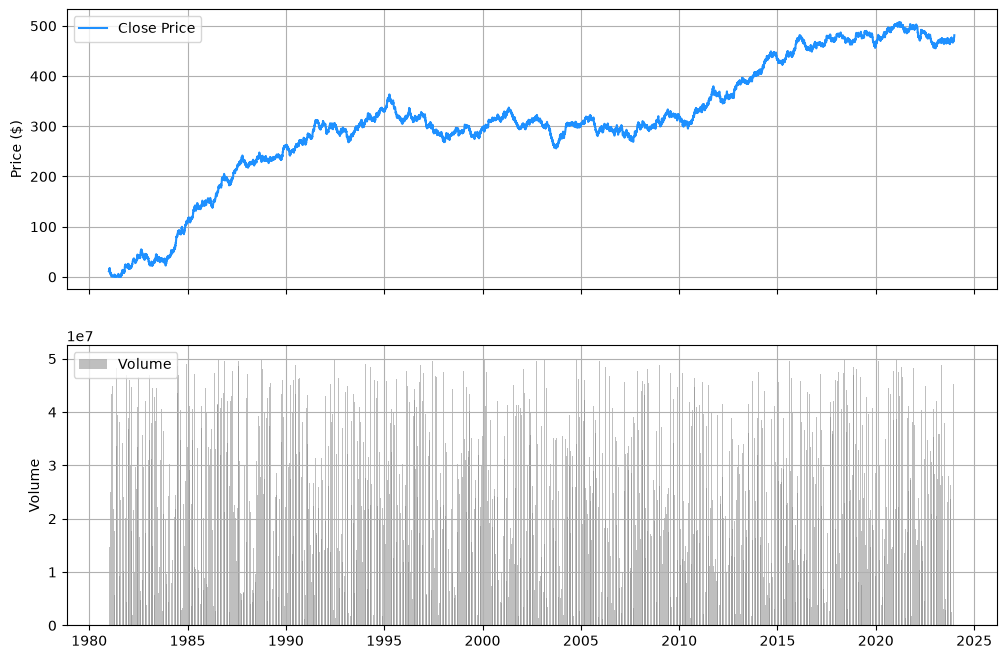

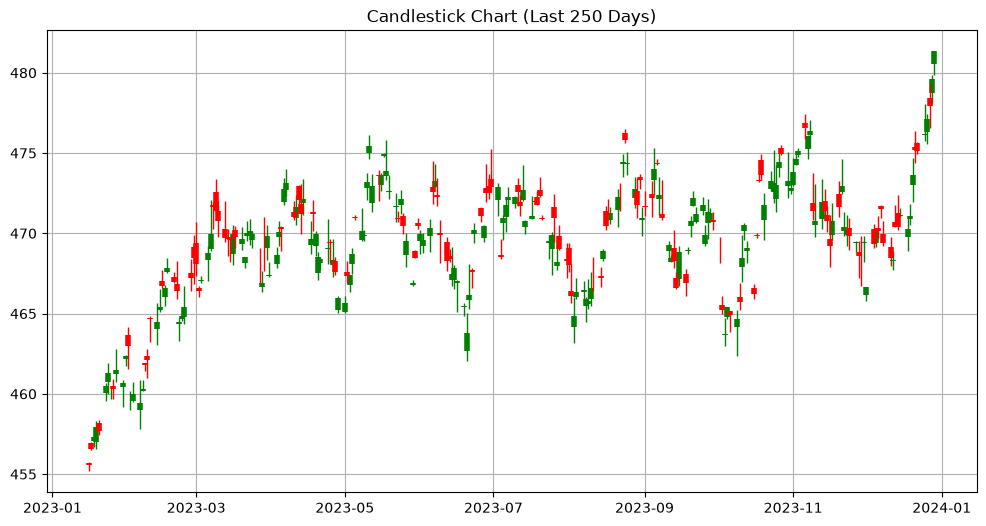

In [2]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.plot(df.index, df['Close'], color='dodgerblue', label='Close Price')
ax1.set_ylabel('Price ($)')
ax1.legend(loc='upper left')
ax1.grid(True)

ax2.bar(df.index, df['Volume'], color='gray', alpha=0.5, width=1.5, label='Volume')
ax2.set_ylabel('Volume')
ax2.legend(loc='upper left')
ax2.grid(True)
plt.show()

df_sample = df.tail(250)
fig, ax = plt.subplots(figsize=(12, 6))
up = df_sample[df_sample['Close'] >= df_sample['Open']]
down = df_sample[df_sample['Close'] < df_sample['Open']]
ax.vlines(up.index, up['Low'], up['High'], color='green', linewidth=1)
ax.vlines(up.index, up['Open'], up['Close'], color='green', linewidth=4)
ax.vlines(down.index, down['Low'], down['High'], color='red', linewidth=1)
ax.vlines(down.index, down['Open'], down['Close'], color='red', linewidth=4)
ax.set_title('Candlestick Chart (Last 250 Days)')
ax.grid(True)
plt.show()

,Open,High,Low,Close,Volume
count,11217.000000,11217.000000,11217.000000,11217.000000,1.121700e+04
mean,308.168939,309.004705,307.330525,308.164003,2.554872e+07
std,122.925675,122.936350,122.938008,122.928908,1.403491e+07
min,-0.864702,0.506220,-1.695331,0.500000,1.000580e+06
25%,274.410911,275.096246,273.613142,274.341186,1.342547e+07
50%,305.401645,306.277540,304.591889,305.336871,2.561979e+07
75%,387.878118,388.646983,387.049225,388.075609,3.755957e+07
max,508.348318,509.510810,506.708863,507.440855,4.999878e+07


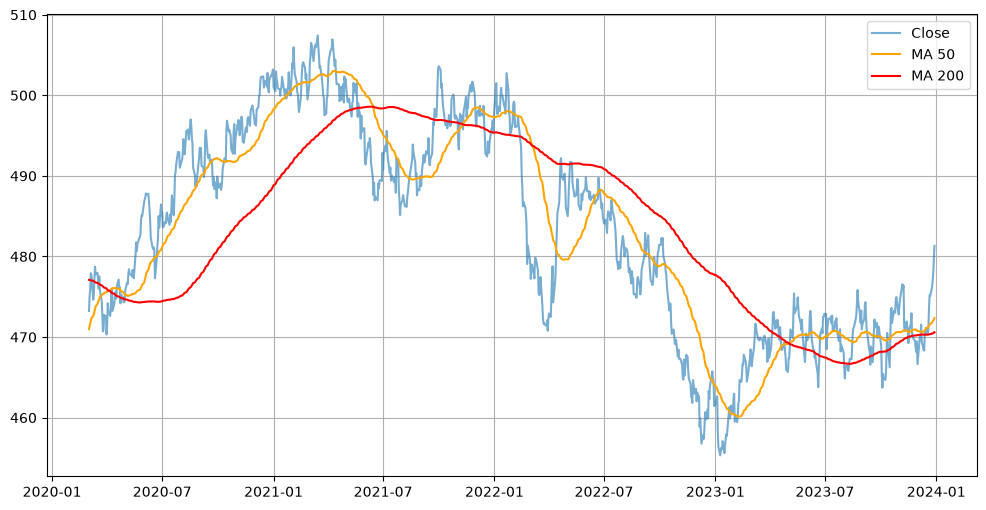

In [3]:
display(df[['Open', 'High', 'Low', 'Close', 'Volume']].describe())

df['MA50'] = df['Close'].rolling(window=50).mean()
df['MA200'] = df['Close'].rolling(window=200).mean()

plt.figure(figsize=(12, 6))
plt.plot(df.index[-1000:], df['Close'].tail(1000), label='Close', alpha=0.6)
plt.plot(df.index[-1000:], df['MA50'].tail(1000), label='MA 50', color='orange')
plt.plot(df.index[-1000:], df['MA200'].tail(1000), label='MA 200', color='red')
plt.legend()
plt.grid(True)
plt.show()

T-test (2020 vs 2022): t = 5.1796, p = 3.1883e-07
Normality Test: statistic = 25599.7086, p = 0.0000e+00


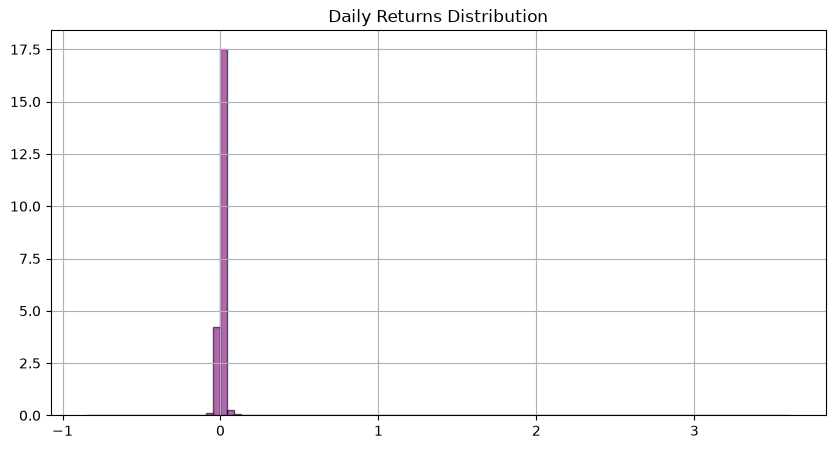

In [4]:
prices_2020 = df.loc['2020-01-01':'2020-12-31']['Close'].dropna()
prices_2022 = df.loc['2022-01-01':'2022-12-31']['Close'].dropna()
t_stat, p_value = stats.ttest_ind(prices_2020, prices_2022, equal_var=False)
print(f"T-test (2020 vs 2022): t = {t_stat:.4f}, p = {p_value:.4e}")

df['Daily_Return'] = df['Close'].pct_change().dropna()
returns = df['Daily_Return'].dropna()
k2, p_norm = stats.normaltest(returns)
print(f"Normality Test: statistic = {k2:.4f}, p = {p_norm:.4e}")

plt.figure(figsize=(10, 5))
plt.hist(returns, bins=100, density=True, alpha=0.6, color='purple', edgecolor='black')
plt.title('Daily Returns Distribution')
plt.grid(True)
plt.show()

In [5]:
window_size = 30
weights = np.repeat(1.0, window_size) / window_size
smoothed_close = np.convolve(df['Close'].values, weights, 'valid')
print(f"Smoothed series length: {len(smoothed_close)}")

valid_data = df[['Close', 'Volume']].dropna()
corr_matrix = np.corrcoef(valid_data['Close'], valid_data['Volume'])
print("Correlation Matrix (Close vs Volume):\n", corr_matrix)

Smoothed series length: 11188
Correlation Matrix (Close vs Volume):
 [[1.        0.0069745]
 [0.0069745 1.       ]]
